# 06 – A LightGBM model: does it beat the rules?

Until now, every forecast was a rule we wrote by hand. Now a **model** learns the rules from the data:
one LightGBM model, trained on all 1,782 series at once, using the feature table from notebook 05.

The bar to beat:
- **0.487**: level + weekday, average RMSLE over our 8 backtest windows;
- **0.41457**: the same rule on Kaggle.

**Plan:**
1. How the model is trained, and how the number of trees is chosen without peeking at the test.
2. Backtest on the same 8 windows as the rules, compared window by window.
3. Where the model wins and loses: by forecast day, and the store 52 window.
4. The earthquake question from notebook 01.
5. What the model uses (feature importance).
6. Submission v2.

*Running time: about 12 minutes on a laptop, mostly the two backtests (each trains 16 models).*

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.baselines import level_and_weekday
from src.data import load_test, load_train
from src.dataset import build_table
from src.features import load_holidays, load_stores
from src.metrics import rmsle
from src.model import PARAMS, backtest_model, feature_columns, fit, forecast, prepare
from src.validation import HORIZON, backtest, make_cutoffs

IMAGES = "../images"

train = load_train()
wide = train.pivot_table(index="date", columns=["store_nbr", "family"], values="sales", observed=True)
data = prepare(build_table(train, load_stores(), load_holidays(), end="2017-08-31"))
print(f"{len(data):,} rows, {len(feature_columns(data))} features:")
print(feature_columns(data))

3,036,528 rows, 24 features:
['store_nbr', 'family', 'lag_16', 'lag_21', 'lag_28', 'lag_364', 'mean_7', 'mean_14', 'mean_28', 'mean_56', 'same_weekday_mean_4', 'same_weekday_mean_8', 'zero_days_28', 'day_of_week', 'day_of_month', 'month', 'days_since_payday', 'national_day_off', 'national_additional', 'national_work_day', 'national_event', 'earthquake', 'regional_holiday', 'local_holiday']


## 1. Training the model

`src/model.py` contains the training code. The important decisions:

- **Target:** `log1p(sales)`. With the ordinary squared-error objective, minimising the error on this scale
  is exactly minimising the RMSLE.
- **One model for all series.** Store and family are **categorical** features, so the model can learn what's
  special about each, while sharing patterns (weekends, paydays, holidays) across all 1,782 series.
  A series with little data borrows strength from the others.
- **Training rows:** from 2015 on. Earlier rows have incomplete features (no "same time last year", little history).
  This wasn't tuned; it's a reasonable starting point.
- **Parameters** (`PARAMS`): common, moderate settings, also not tuned.

In [2]:
PARAMS

{'objective': 'regression',
 'learning_rate': 0.05,
 'num_leaves': 63,
 'min_data_in_leaf': 100,
 'feature_fraction': 0.8,
 'bagging_fraction': 0.8,
 'bagging_freq': 1,
 'seed': 0,
 'verbose': -1}

### How many trees? Without peeking.

LightGBM adds trees one by one, each correcting the previous ones. Too few trees underfit, too many overfit.
The usual tool is **early stopping**: watch the error on validation data and stop when it no longer improves.

**The trap:** if the validation data is the forecast period itself, we have tuned on the test, and the backtest
score is too optimistic. (The same mistake as choosing rule settings from the backtest results, step 4.)

`fit()` avoids it:
1. hold out the **last 16 days before the cutoff** as an inner validation period;
2. train on the data before it, with early stopping on the inner period → number of trees;
3. retrain on **all** data up to the cutoff with that number of trees.

The forecast period is never touched. Let's train once, at the cutoff of notebook 02's validation period:

In [3]:
cutoff = pd.Timestamp("2017-07-30")
model, n_trees = fit(data, cutoff)
dates = pd.date_range(cutoff + pd.Timedelta(days=1), periods=HORIZON, name="date")
predicted = forecast(model, data, dates)

print(f"Trees chosen by early stopping: {n_trees}")
print(f"LightGBM:        RMSLE {rmsle(wide.loc[dates, predicted.columns], predicted):.4f}")
print(f"Level + weekday: RMSLE {rmsle(wide.loc[dates], level_and_weekday(wide.loc[:cutoff], dates)):.4f}")

Trees chosen by early stopping: 470
LightGBM:        RMSLE 0.4715
Level + weekday: RMSLE 0.5244


On this window the model is clearly better (about 0.47 against 0.52), even though it only uses sales at least
16 days old while the rule uses everything up to the cutoff. But one window proved nothing in notebook 03 either.

## 2. Backtest on 8 windows

The same 8 windows as in notebook 03. For each, `backtest_model` trains a new model on the data up to the cutoff
(with its own early stopping) and scores the next 16 days. This takes about 5 minutes.

In [4]:
cutoffs = make_cutoffs(wide.index.max(), n_windows=8)
model_scores, model_forecasts = backtest_model(data, wide, cutoffs)
rule_scores = backtest(wide, {"Level + weekday": level_and_weekday}, cutoffs)

results = pd.DataFrame({
    "LightGBM": model_scores["RMSLE"],
    "Level + weekday": rule_scores["Level + weekday"],
    "trees": model_scores["trees"].astype(int),
})
results["difference"] = results["LightGBM"] - results["Level + weekday"]
results.round(3)

,LightGBM,Level + weekday,trees,difference
window starts,,,,
2017-04-10,0.608,0.626,82,-0.018
2017-04-26,0.696,0.596,66,0.099
2017-05-12,0.433,0.485,679,-0.053
2017-05-28,0.403,0.422,2066,-0.020
2017-06-13,0.395,0.414,1283,-0.019
2017-06-29,0.384,0.406,1340,-0.022
2017-07-15,0.408,0.420,1051,-0.012
2017-07-31,0.472,0.524,470,-0.053


Mean RMSLE: LightGBM 0.4745, level + weekday 0.4867
LightGBM better in 7 of 8 windows


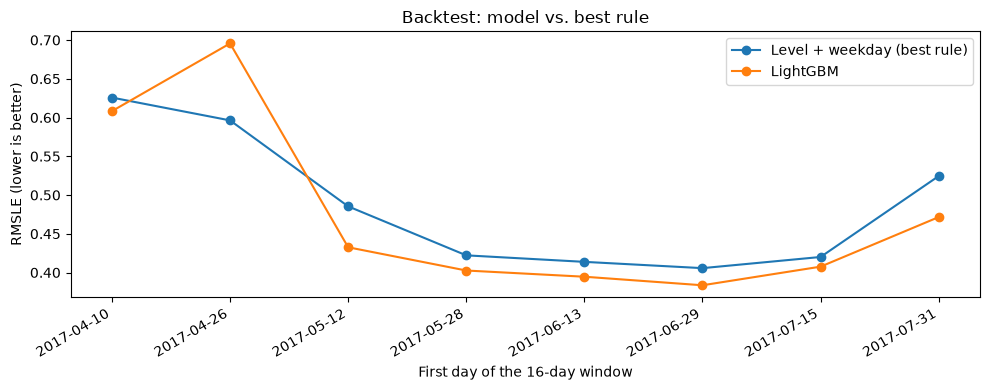

In [5]:
print(f"Mean RMSLE: LightGBM {results['LightGBM'].mean():.4f}, level + weekday {results['Level + weekday'].mean():.4f}")
print(f"LightGBM better in {(results['difference'] < 0).sum()} of {len(results)} windows")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(results.index, results["Level + weekday"], marker="o", label="Level + weekday (best rule)")
ax.plot(results.index, results["LightGBM"], marker="o", label="LightGBM")
ax.set_ylabel("RMSLE (lower is better)")
ax.set_xlabel("First day of the 16-day window")
ax.set_title("Backtest: model vs. best rule")
ax.legend()
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
fig.savefig(f"{IMAGES}/model_vs_rule.png", dpi=120)
plt.show()

**What we found:**
- **The model wins 7 of 8 windows**, usually by 0.01–0.05, and lowers the mean RMSLE from 0.487 to about 0.475.
- **It loses one window badly: the late-April window** (about 0.70 against 0.60). That's the store 52 window
  from notebook 05: the store opened on 20 April, and the model's features (16+ days old) still say "closed".
  The rule, which uses data up to the cutoff, sees the store open.

Store 52 also opens *inside* the first window (on its 11th day), where neither method can know it. How much of the
April difficulty is store 52? Let's score both methods without it:

In [6]:
without_52 = wide.columns[wide.columns.get_level_values("store_nbr") != 52]
no_52 = pd.DataFrame({
    "LightGBM": [rmsle(wide.loc[model_forecasts[w].index, without_52], model_forecasts[w][without_52]) for w in results.index],
    "Level + weekday": [rmsle(wide.loc[model_forecasts[w].index, without_52],
                              level_and_weekday(wide.loc[:c], model_forecasts[w].index)[without_52])
                        for w, c in zip(results.index, cutoffs)],
}, index=results.index)
no_52["difference"] = no_52["LightGBM"] - no_52["Level + weekday"]
print(f"Without store 52, LightGBM is better in {(no_52['difference'] < 0).sum()} of {len(no_52)} windows")
no_52.round(3)

Without store 52, LightGBM is better in 8 of 8 windows


,LightGBM,Level + weekday,difference
window starts,,,
2017-04-10,0.444,0.466,-0.022
2017-04-26,0.456,0.458,-0.002
2017-05-12,0.431,0.484,-0.053
2017-05-28,0.402,0.420,-0.018
2017-06-13,0.395,0.412,-0.017
2017-06-29,0.384,0.407,-0.022
2017-07-15,0.408,0.421,-0.013
2017-07-31,0.473,0.527,-0.054


**Without store 52, the model wins all 8 windows**, by about 0.03 on average, and the April windows are no longer
unusually hard (about 0.44–0.46 instead of 0.61–0.70). So in notebook 03, the difficulty of the April windows was
mostly one new store, not Easter as we guessed there. One store out of 54 can move a whole window's score:
another reason to look at *which series* cause the error, not only at the total.

The model's overall advantage is therefore small **because of one store opening**, the cost of the 16-day rule
(approach A) showing up exactly as measured in notebook 05.

**The number of trees varies a lot** (see the `trees` column of the first table): from under 100 to about 2,000.
The late-April window stopped very early: its inner validation period (10–25 April) contains store 52's opening,
where no number of trees helps. The first window also stopped early, and its inner period has no obvious event;
we don't know why. Either way, **early stopping is only as good as its validation period**, and a single 16-day period
is noisy. A more robust choice (e.g. several inner periods) is a possible improvement.

## 3. Where does the model win? By forecast day

The model always uses 16-day-old data; the rule uses data up to the cutoff. So we'd expect the rule to be
relatively better on the **first** forecast days (where its data is fresher) and the model better later.
We average over all 8 windows, leaving out store 52, whose opening would dominate the picture.

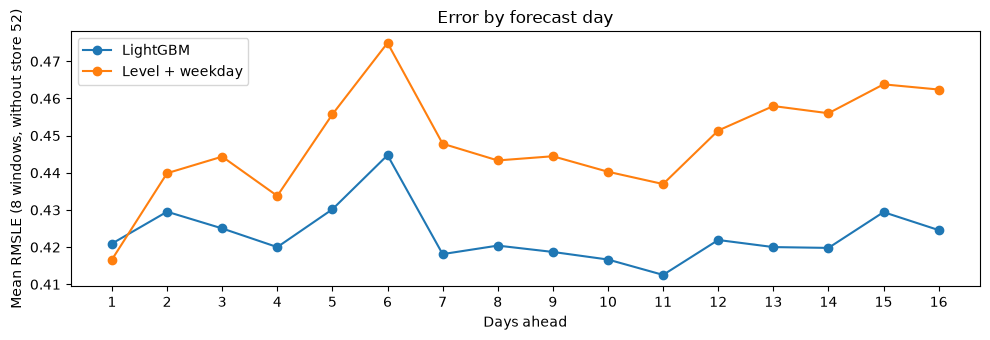

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
model minus rule,0.004,-0.01,-0.019,-0.014,-0.026,-0.03,-0.03,-0.023,-0.026,-0.024,-0.024,-0.029,-0.038,-0.036,-0.034,-0.038


In [7]:
per_day = {"LightGBM": [], "Level + weekday": []}
for day in range(HORIZON):
    model_errors, rule_errors = [], []
    for window, cutoff in zip(results.index, cutoffs):
        date = cutoff + pd.Timedelta(days=day + 1)
        actual = wide.loc[date, without_52]
        model_errors.append(rmsle(actual, model_forecasts[window].loc[date, without_52]))
        rule = level_and_weekday(wide.loc[:cutoff], pd.DatetimeIndex([date])).iloc[0]
        rule_errors.append(rmsle(actual, rule[without_52]))
    per_day["LightGBM"].append(np.mean(model_errors))
    per_day["Level + weekday"].append(np.mean(rule_errors))
per_day = pd.DataFrame(per_day, index=range(1, HORIZON + 1))

fig, ax = plt.subplots(figsize=(10, 3.5))
for name in per_day.columns:
    ax.plot(per_day.index, per_day[name], marker="o", label=name)
ax.set_xlabel("Days ahead")
ax.set_ylabel("Mean RMSLE (8 windows, without store 52)")
ax.set_xticks(per_day.index)
ax.set_title("Error by forecast day")
ax.legend()
fig.tight_layout()
fig.savefig(f"{IMAGES}/model_by_horizon.png", dpi=120)
plt.show()
(per_day["LightGBM"] - per_day["Level + weekday"]).round(3).rename("model minus rule").to_frame().T

**What we found:** on **day 1 the rule is slightly better** (by about 0.004). From day 2 on the model wins,
and its lead grows with the horizon, to about 0.035 in the second week. The model's error stays almost flat
(its data is 16 days old for every day anyway), while the rule's grows as its fresh data ages.
The rule's fresher data helps most at the start, exactly as expected.

*A lesson from making this chart:* the first version included store 52 and showed a sudden jump at day 11 for
both methods. Day 11 of the first window is 20 April, the day store 52 opened. A jump that hits every method
at the same point usually means an event in the data, not something about the methods.

This points to the main remaining improvement: give the model fresher data for the first days
(approach B from notebook 05). We note it and keep going.

## 4. The earthquake question

Notebook 01 asked whether to drop the weeks after the April 2016 earthquake from training. We postponed the
decision until we could measure it. Now we can: rerun the backtest without 16 April – 31 May 2016 in the training data
(about 6 minutes).

In [8]:
without_quake, _ = backtest_model(data, wide, cutoffs, exclude=("2016-04-16", "2016-05-31"))
quake = pd.DataFrame({"with earthquake weeks": results["LightGBM"], "without": without_quake["RMSLE"]})
quake.loc["mean"] = quake.mean()
quake.round(4)

,with earthquake weeks,without
window starts,,
2017-04-10,0.6083,0.6071
2017-04-26,0.6956,0.6984
2017-05-12,0.4326,0.4376
2017-05-28,0.4026,0.4019
2017-06-13,0.3946,0.3947
2017-06-29,0.3836,0.3835
2017-07-15,0.4076,0.4070
2017-07-31,0.4715,0.4731
mean,0.4745,0.4754


**No meaningful difference** (the means differ by about 0.001, less than the window-to-window noise).
The `earthquake` flag from step 5 seems to be enough for the model to treat those weeks as special.
**Decision: keep the data.** Simpler is better when it costs nothing.

## 5. What does the model use?

**Gain importance**: how much each feature reduced the training error, summed over all trees.
We use the model trained at the 2017-07-30 cutoff from section 1.

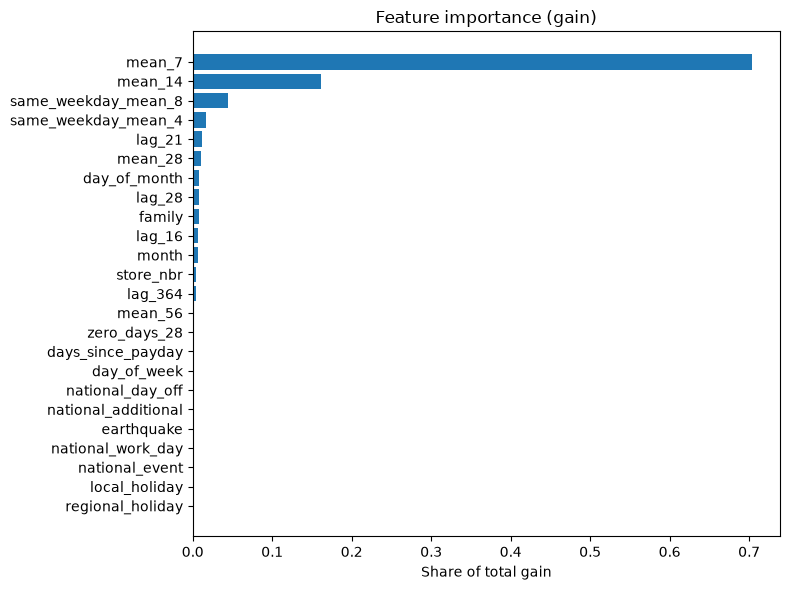

mean_7                 0.704
mean_14                0.162
same_weekday_mean_8    0.044
same_weekday_mean_4    0.016
lag_21                 0.012
mean_28                0.011
day_of_month           0.008
lag_28                 0.008
dtype: float64

In [9]:
importance = pd.Series(model.feature_importance("gain"), index=feature_columns(data))
importance = (importance / importance.sum()).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importance.index, importance.values)
ax.set_xlabel("Share of total gain")
ax.set_title("Feature importance (gain)")
fig.tight_layout()
fig.savefig(f"{IMAGES}/feature_importance.png", dpi=120)
plt.show()
importance.sort_values(ascending=False).head(8).round(3)

**What we found:** the recent averages, `mean_7` and `mean_14`, carry most of the gain: the model's first job is
"how much does this series sell lately?". Then come the same-weekday features (the weekly pattern) and a long tail
of calendar features, family and store.

*Two cautions about importance:*
- **It isn't the same as usefulness.** Correlated features (all the means) share the credit; removing `mean_7`
  would let `mean_14` take over, with little loss.
- **Small importance doesn't mean useless.** Holiday flags matter on a few days a year, so their total gain is small,
  but on those days they can matter a lot.

## 6. Submission v2

To forecast the real test period, we train one last model at the real cutoff, **15 August 2017** (the last day of train),
with the same `fit()` (early stopping on 31 July – 15 August, then retraining on everything).

In [10]:
final_model, final_trees = fit(data, "2017-08-15")
test = load_test()
test_dates = pd.DatetimeIndex(sorted(test["date"].unique()), name="date")
predicted = forecast(final_model, data, test_dates)
print(f"Trees: {final_trees}")

long = predicted.unstack().rename("sales").reset_index()
submission = test.merge(long, on=["store_nbr", "family", "date"], how="left")[["id", "sales"]]

assert len(submission) == len(test)
assert submission["sales"].notna().all()
assert (submission["sales"] >= 0).all()

submission.to_csv("../submissions/v2_lightgbm.csv", index=False)
submission.head()

Trees: 2540


,id,sales
0,3000888,4.098591
1,3002670,3.785161
2,3004452,4.493256
3,3006234,4.634371
4,3008016,1.846188


Early stopping chose 2,540 trees this time, within the range seen in the backtest.

Upload `submissions/v2_lightgbm.csv` to Kaggle. What to expect: the backtest says the model is about 0.01 better
than level + weekday on average, and about 0.03 better when no store has just opened. No store opened in the weeks
before the test period, so a Kaggle score below 0.41457 is likely, but not guaranteed: one score is just one more window.

## Summary

| Finding | Consequence |
|---|---|
| LightGBM beats level + weekday in 7 of 8 windows, mean 0.487 → 0.475 | The first model that beats the rules |
| Without store 52 it wins all 8 windows, by ~0.03 | One new store explains the "hard" April windows |
| It loses badly on the window just after store 52 opened | The cost of 16-day-old features (approach A), as measured in notebook 05 |
| Its lead is smallest on the first forecast days | Fresher data for early days (approach B) is the main improvement left |
| Early stopping chose 66 – 2,540 trees | A single 16-day inner validation period is noisy |
| Dropping the earthquake weeks changes nothing | Keep the data |
| Recent averages carry most of the importance | The model's first job is the series' recent level |

**Next step (step 8):** extra data. Promotions (`onpromotion`, known in advance for the test period), oil prices,
store types: do they help the model?